<a href="https://colab.research.google.com/github/naravinvh/01204223-flask-react-todo-68/blob/main/final_project_6710503895.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adaptive Mono-to-Stereo Audio Processing Using Spectral Analysis


## 1. Setup

In [1]:
import os, sys
if "google.colab" in sys.modules:
    %pip install -q pyloudnorm
    if not os.path.isdir("audio"):
        from google.colab import files
        files.upload()
        !unzip -q -o dsp_colab_data.zip

Saving dsp_colab_data.zip to dsp_colab_data.zip


In [2]:
import csv, json
from pathlib import Path
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import pyloudnorm as pyln
from scipy.signal import firwin
from scipy.stats import binomtest, friedmanchisquare
from IPython.display import Audio, display

FS, NFFT = (44100, 4096)
FRAME, HOP, N_BANDS, BAND = (4096, 512, 24, (100.0, 12000.0))
SF_LO, SF_HI, GATE = (0.01, 0.5, 0.001)
G_MIN, G_MAX = (0.1, 0.9)
D_MS, G_FIX, P_PAN, FC = (12.0, 0.7, 0.8, 800.0)
D = round(D_MS * FS / 1000)
AUDIO, FIG = (Path('audio'), Path('figures'))
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 9})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f'{name}.png', dpi=200)
    plt.show()

def table(rows, cols, w=11):
    print(f"{'':22s}" + ''.join((f'{c:>{w}s}' for c in cols)))
    for name, r in rows.items():
        print(f'{name:22s}' + ''.join((f'{r[c]:>{w}.4f}' if isinstance(r[c], float) else f'{r[c]!s:>{w}s}' for c in cols)))


## 2. Test signals
สัญญาณสังเคราะห์ 8 วินาที (Chord / Noise / Mixed / Voice ช่วงละ 2 วินาที) และเสียงจริง 9 ไฟล์ (ช่วง 20 วินาทีที่ดังที่สุด)

In [3]:
def synth(seed=0):
    rng, n = (np.random.default_rng(seed), 2 * FS)
    t = np.arange(n) / FS
    chord = sum((np.sin(2 * np.pi * f * t) for f in (220.0, 277.18, 329.63))) / 3
    noise = np.convolve(rng.normal(0, 1, n), firwin(255, [2000, 8000], pass_zero=False, fs=FS), mode='same')
    noise = 0.9 * noise / np.abs(noise).max()
    phase = 2 * np.pi * np.cumsum(130 * (1 + 0.02 * np.sin(2 * np.pi * 5 * t))) / FS
    voice = sum((np.sin(k * phase) / k for k in range(1, 12))) * 0.5 * (1 - np.cos(2 * np.pi * 2.5 * t)) ** 0.5
    x = np.concatenate([chord, noise, 0.6 * chord + 0.4 * noise, voice])
    return 0.7 * x / np.abs(x).max()

def load(path, sec=20.0):
    # mono, 44.1 kHz, loudest `sec` seconds (None = whole file), peak 0.7
    d, fs = sf.read(path, always_2d=True)
    x = d.mean(axis=1)
    if fs != FS:
        x = np.interp(np.arange(int(len(x) * FS / fs)) / FS, np.arange(len(x)) / fs, x)
    n = int(sec * FS) if sec else len(x)
    if len(x) > n:
        e = np.cumsum(np.concatenate([[0.0], x ** 2]))
        s = np.arange(0, len(x) - n, FS // 2)
        x = x[s[np.argmax(e[s + n] - e[s])]:][:n]
    return 0.7 * x / np.abs(x).max()
x = synth()
SEGS = {'chord': (0, 2), 'noise': (2, 4), 'mix': (4, 6), 'voice': (6, 8)}
FILES = {p.stem: p for p in sorted(AUDIO.iterdir()) if p.suffix in ('.wav', '.mp3')}
clips = {k: load(p) for k, p in FILES.items()}
print(f"synthetic {len(x) / FS:.0f} s | real clips: {', '.join(clips)}")


synthetic 8 s | real clips: mono1963_beatles_twist, piano_solo_golden_hour, rain_ambience, rock_band_retrospect, speech_en_samantha, speech_th_kanya, strings_ensemble_howl, violin_solo_bach_hahn, vocal_guitar_memories


## 3. Spectral analysis (FFT, Welch PSD/CSD, Coherence)

In [4]:
def frames(x, n=FRAME, hop=HOP):
    if len(x) < n:
        x = np.pad(x, (0, n - len(x)))
    return x[np.arange(n) + hop * np.arange(1 + (len(x) - n) // hop)[:, None]]

def csd(a, b, n=NFFT):
    w = np.hanning(n)
    A, B = (np.fft.rfft(frames(s, n, n // 2) * w, axis=1) for s in (a, b))
    P = np.mean(A * np.conj(B), axis=0) / (FS * np.sum(w ** 2))
    P[1:-1] *= 2
    return (np.fft.rfftfreq(n, 1 / FS), P)

def psd(a, n=NFFT):
    f, P = csd(a, a, n)
    return (f, P.real)

def coherence(L, R, n=NFFT):
    f, P = csd(L, R, n)
    return (f, np.abs(P) ** 2 / (psd(L, n)[1] * psd(R, n)[1] + 1e-30))
v = np.random.default_rng(42).normal(0, 0.5, 8 * FS)
f, P = psd(v)
print(f'white noise: PSD {P.mean():.3e} (theory {0.25 / (FS / 2):.3e}), power {np.trapezoid(P, f):.4f}, coherence(v, v) {coherence(v, v)[1].mean():.4f}')


white noise: PSD 1.133e-05 (theory 1.134e-05), power 0.2500, coherence(v, v) 1.0000


## 4. Methods M0–M4
$L = x + g\,x[n-D]$, $R = x - g\,x[n-D]$ สำหรับ M2 (g คงที่) และ M4 (g[n] จาก Spectral Flatness)

In [5]:
def delay(x, d=D):
    y = np.zeros(len(x))
    if d < len(x):
        y[d:] = x[:len(x) - d]
    return y


def mid_side(x, g, d=D):
    side = g * delay(x, d)
    return x + side, x - side


def m0(x):
    return x.copy(), x.copy()


def m1(x):
    return x.copy(), delay(x)


def m2(x, g=G_FIX):
    return mid_side(x, g)


def m3(x, p=P_PAN):
    low = np.convolve(x, firwin(255, FC, fs=FS), mode="same")
    high = x - low
    left = low + (1 - p) * high
    right = (1 - p) * low + high
    return left, right


def features(x, n=FRAME):
    # Energy-weighted spectral flatness and RMS for each frame.
    fr = frames(x, n)
    power = np.abs(np.fft.rfft(fr * np.hanning(n), axis=1)) ** 2 + 1e-20
    freq = np.fft.rfftfreq(n, 1 / FS)

    bands = power[:, (freq >= BAND[0]) & (freq <= BAND[1])]
    bins = bands.shape[1] // N_BANDS
    bands = bands[:, :bins * N_BANDS].reshape(len(power), N_BANDS, bins)

    geometric = np.exp(np.mean(np.log(bands), axis=2))
    arithmetic = np.mean(bands, axis=2)
    weights = arithmetic / (np.sum(arithmetic, axis=1, keepdims=True) + 1e-30)

    flatness = np.sum(weights * (geometric / arithmetic), axis=1)
    rms = np.sqrt(np.mean(fr ** 2, axis=1))
    times = (np.arange(len(power)) * HOP + n / 2) / FS
    return times, flatness, rms


def noisiness(flatness):
    score = (np.log10(flatness) - np.log10(SF_LO)) / (
        np.log10(SF_HI) - np.log10(SF_LO)
    )
    return np.clip(score, 0, 1)


def m4(x):
    # Return left, right, sample gain, and frame gain.
    times, flatness, rms = features(x)
    frame_gain = G_MIN + (G_MAX - G_MIN) * noisiness(flatness)
    frame_gain[rms < GATE] = G_MIN

    # Align gain with the delayed audio content.
    gain = np.interp((np.arange(len(x)) - D) / FS, times, frame_gain)
    left, right = mid_side(x, gain)
    return left, right, gain, frame_gain


def matched_gain(x, gain):
    # Match the total Side energy using a constant gain.
    delayed = delay(x)
    energy = np.sum(delayed ** 2)
    if energy <= 1e-20:
        return 0.0
    return float(np.sqrt(np.sum((gain * delayed) ** 2) / energy))


## 5. Metrics

In [6]:
def icc(L, R):
    return np.nan if min(L.std(), R.std()) < 1e-12 else float(np.corrcoef(L, R)[0, 1])

def xcorr_max(L, R, ms=1.0):
    n, nf = (len(L), 1 << int(np.ceil(np.log2(2 * len(L) - 1))))
    r = np.fft.irfft(np.fft.rfft(L, nf) * np.conj(np.fft.rfft(R, nf)), nf)
    r = np.concatenate([r[-(n - 1):], r[:n]])
    m = int(FS * ms / 1000)
    return float(np.max(np.abs(r[n - 1 - m:n + m])) / np.sqrt(np.sum(L ** 2) * np.sum(R ** 2)))

def sm_db(L, R):
    S, M = (np.sum(((L - R) / 2) ** 2), np.sum(((L + R) / 2) ** 2))
    return np.nan if M == 0 else -np.inf if S == 0 else float(10 * np.log10(S / M))

def spec_dev(x, y, band=(20.0, 16000.0)):
    # RMS of 10log10(P_y/P_x) after removing the median (shape change only)
    f, Px = psd(x)
    r = 10 * np.log10((psd(y)[1] + 1e-30) / (Px + 1e-30))[(f >= band[0]) & (f <= band[1])]
    return float(np.sqrt(np.mean((r - np.median(r)) ** 2)))

def evaluate(x, L, R):
    st = np.stack([L, R])
    return {'ICC': icc(L, R), 'xcorr±1ms': xcorr_max(L, R), 'coherence': float(coherence(L, R)[1].mean()), 'mono RMSE': float(np.sqrt(np.mean(((L + R) / 2 - x) ** 2))), 'mono gain': float(np.dot((L + R) / 2, x) / np.dot(x, x)), 'E_mono': spec_dev(x, (L + R) / 2), 'E_L': spec_dev(x, L), 'E_R': spec_dev(x, R), 'S/M': sm_db(L, R), 'peak': float(np.abs(st).max()), 'clip%': float(100 * np.mean(np.abs(st) > 1))}

def by_class(x, L, R):
    # S/M and ICC over tonal / noisy frames (same classifier as M4)
    _, s, rms = features(x)
    nz, S, M, fl, fr = (noisiness(s), frames((L - R) / 2), frames((L + R) / 2), frames(L), frames(R))
    out = {}
    for c, m in (('tonal', (nz < 0.5) & (rms >= GATE)), ('noisy', (nz >= 0.5) & (rms >= GATE))):
        out[f'S/M {c}'] = float(10 * np.log10(np.sum(S[m] ** 2) / np.sum(M[m] ** 2))) if m.any() else np.nan
        out[f'ICC {c}'] = icc(fl[m].ravel(), fr[m].ravel()) if m.any() else np.nan
    return out

def fair(x):
    # Experiment A (M2, g0 = 0.7) and B (M2 matched) vs M4
    L4, R4, g4, _ = m4(x)
    gm = matched_gain(x, g4)
    out = {'M2 fixed': (m2(x), G_FIX), 'M2 matched': (m2(x, gm), gm), 'M4 adaptive': ((L4, R4), g4)}
    return {k: {'LR': lr, 'g': float(np.mean(g)), **evaluate(x, *lr), **by_class(x, *lr), 'side energy': float(np.sum(((lr[0] - lr[1]) / 2) ** 2))} for k, (lr, g) in out.items()}


## 6. ผลบนสัญญาณสังเคราะห์

In [7]:
L4, R4, g4, gf4 = m4(x)
out = {'M0 Mono Copy': m0(x), 'M1 Haas Delay': m1(x), 'M2 Fixed Gain': m2(x), 'M3 Two-band Panning': m3(x), 'M4 Adaptive Gain': (L4, R4)}
res = {k: evaluate(x, *lr) for k, lr in out.items()}
res['M3 (gain compensated)'] = evaluate(x, *(s * 2 / (2 - P_PAN) for s in out['M3 Two-band Panning']))
exp = fair(x)
res['M2 Matched'] = {k: exp['M2 matched'][k] for k in res['M0 Mono Copy']}
table(res, ['ICC', 'mono RMSE', 'mono gain', 'S/M', 'xcorr±1ms', 'coherence', 'E_L', 'E_R', 'E_mono', 'peak'])
t, s, rms = features(x)
print('\nmean SF / noisiness per segment')
for k, (a, b) in SEGS.items():
    m = (t >= a) & (t < b)
    print(f'  {k:6s} {s[m].mean():.4f}  {noisiness(s[m]).mean():.2f}')
print(f'white noise SF median {np.median(features(np.random.default_rng(7).normal(0, 0.5, 4 * FS))[1]):.3f} (theory e^-γ = {np.exp(-np.euler_gamma):.3f}), sine SF {features(np.sin(2 * np.pi * 440 * np.arange(4 * FS) / FS))[1].mean():.1e}')


                              ICC  mono RMSE  mono gain        S/M  xcorr±1ms  coherence        E_L        E_R     E_mono       peak
M0 Mono Copy               1.0000     0.0000     1.0000       -inf     1.0000     1.0000     0.0000     0.0000     0.0000     0.7000
M1 Haas Delay             -0.2309     0.1546     0.3845     2.0427     0.3052     0.8300     0.0000     1.2233     4.3006     0.7000
M2 Fixed Gain              0.3506     0.0000     1.0000    -3.0981     0.3506     0.7737     3.4267     3.4146     0.0000     0.8069
M3 Two-band Panning        0.5519     0.0788     0.6000    -3.6069     0.5519     0.9999     3.0659     2.8395     0.0000     0.6187
M4 Adaptive Gain           0.8045     0.0000     1.0000    -9.6298     0.8045     0.7290     3.4968     3.4756     0.0000     0.7187
M3 (gain compensated)      0.5519     0.0000     1.0000    -3.6069     0.5519     0.9999     3.0659     2.8395     0.0000     1.0312
M2 Matched                 0.8113     0.0000     1.0000    -9.6298   

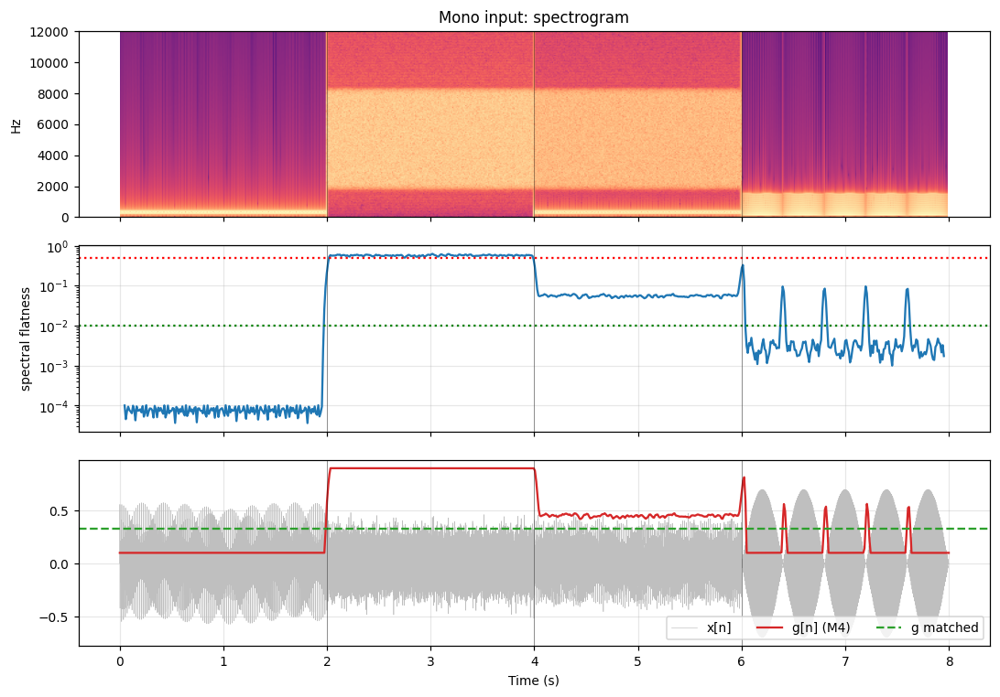

In [8]:
tt = np.arange(len(x)) / FS
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].specgram(x, NFFT=1024, Fs=FS, noverlap=512, cmap='magma')
ax[0].set_ylim(0, 12000)
ax[0].set_ylabel('Hz')
ax[0].grid(False)
ax[0].set_title('Mono input: spectrogram')
ax[1].semilogy(t, s)
ax[1].axhline(SF_LO, ls=':', c='g')
ax[1].axhline(SF_HI, ls=':', c='r')
ax[1].set_ylabel('spectral flatness')
ax[2].plot(tt, x, c='0.75', lw=0.4, label='x[n]')
ax[2].plot(tt, g4, c='C3', label='g[n] (M4)')
ax[2].axhline(exp['M2 matched']['g'], c='C2', ls='--', label='g matched')
ax[2].set_xlabel('Time (s)')
ax[2].legend(loc='lower right', ncol=3)
for a in ax:
    [a.axvline(b, c='k', lw=0.6, alpha=0.4) for b in (2, 4, 6)]
save(fig, 'adaptive_gain')


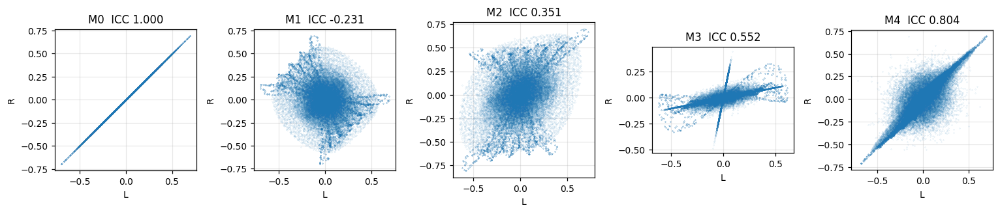

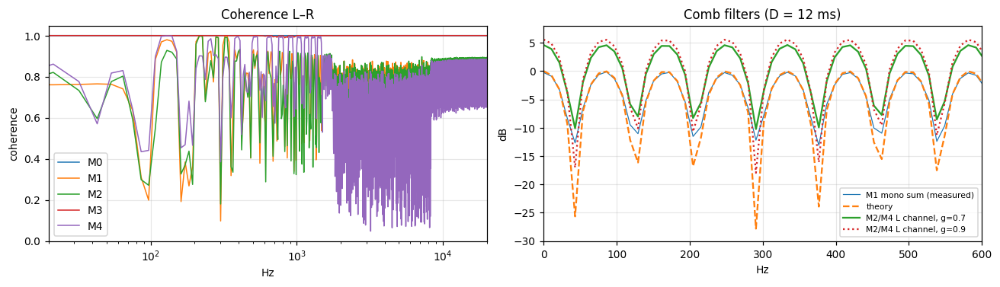

comb spacing f_s/D = 83.4 Hz
  g = 0.10: peak +0.83 dB, notch -0.92 dB
  g = 0.33: peak +2.48 dB, notch -3.48 dB
  g = 0.70: peak +4.61 dB, notch -10.46 dB
  g = 0.90: peak +5.58 dB, notch -20.00 dB


In [9]:
fig, ax = plt.subplots(1, 5, figsize=(14, 3))
for a, (k, (L, R)) in zip(ax, out.items()):
    a.plot(L[::8], R[::8], '.', ms=0.4, alpha=0.3)
    a.set_aspect('equal')
    a.set_title(f'{k.split()[0]}  ICC {icc(L, R):.3f}')
    a.set_xlabel('L')
    a.set_ylabel('R')
save(fig, 'lissajous')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for k, (L, R) in out.items():
    f, c = coherence(L, R)
    ax[0].semilogx(f[1:], c[1:], lw=1, label=k.split()[0])
ax[0].set(xlim=(20, 20000), xlabel='Hz', ylabel='coherence', title='Coherence L–R')
ax[0].legend()
f, Px = psd(v)
ax[1].plot(f, 10 * np.log10(psd((v + delay(v)) / 2)[1] / Px), lw=0.8, label='M1 mono sum (measured)')
ax[1].plot(f, 20 * np.log10(np.abs(np.cos(np.pi * f * D / FS)) + 1e-12), '--', label='theory')
for gg, ls in ((0.7, '-'), (0.9, ':')):
    ax[1].plot(f, 10 * np.log10(1 + gg ** 2 + 2 * gg * np.cos(2 * np.pi * f * D / FS)), ls, label=f'M2/M4 L channel, g={gg}')
ax[1].set(xlim=(0, 600), ylim=(-30, 8), xlabel='Hz', ylabel='dB', title='Comb filters (D = 12 ms)')
ax[1].legend(fontsize=7)
save(fig, 'coherence_comb')
print(f'comb spacing f_s/D = {FS / D:.1f} Hz')
for gg in (0.1, 0.33, 0.7, 0.9):
    print(f'  g = {gg:4.2f}: peak {20 * np.log10(1 + gg):+.2f} dB, notch {20 * np.log10(1 - gg):+.2f} dB')


## 7. Fixed vs Adaptive (Experiment A และ B)
B: M2 Matched มีพลังงาน Side รวมเท่ากับ M4 ต่างกันแค่ว่า Gain เปลี่ยนตามเวลาหรือไม่

                                 g side energy         ICC   ICC tonal   ICC noisy         S/M   S/M tonal   S/M noisy   coherence   mono RMSE
M2 fixed                    0.7000   6710.2717      0.3506      0.3527      0.3358     -3.0981     -3.1002     -3.0339      0.7737      0.0000
M2 matched                  0.3300   1491.3156      0.8113      0.8131      0.8010     -9.6298     -9.6319     -9.5656      0.9441      0.0000
M4 adaptive                 0.4007   1491.3156      0.8045      0.9228      0.1451     -9.6298    -13.8878     -1.2695      0.7290      0.0000

ICC chord      0.3455     0.8050     0.9773
ICC noise      0.3332     0.7999     0.1011
ICC mix        0.3437     0.8043     0.6532
ICC voice      0.3866     0.8413     0.9819

mean coherence vs Welch window (a 12 ms delay biases short windows; only M4 stays below 1)
  M2 fixed      N=4096: 0.774  N=16384: 0.964  N=65536: 0.998
  M2 matched    N=4096: 0.944  N=16384: 0.994  N=65536: 1.000
  M4 adaptive   N=4096: 0.729  N=16

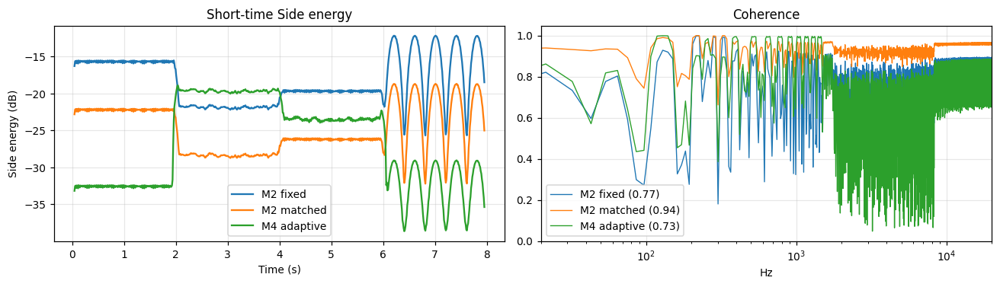

In [10]:
cols = ['g', 'side energy', 'ICC', 'ICC tonal', 'ICC noisy', 'S/M', 'S/M tonal', 'S/M noisy', 'coherence', 'mono RMSE']
table(exp, cols, 12)
print()
for k, (a, b) in SEGS.items():
    sl = slice(a * FS, b * FS)
    print(f'ICC {k:6s}' + ''.join((f"{icc(r['LR'][0][sl], r['LR'][1][sl]):11.4f}" for r in exp.values())))
print('\nmean coherence vs Welch window (a 12 ms delay biases short windows; only M4 stays below 1)')
for k, r in exp.items():
    print(f'  {k:12s}' + ''.join((f"  N={n}: {coherence(*r['LR'], n)[1].mean():.3f}" for n in (4096, 16384, 65536))))
d = delay(x)
print('\nwhy g_matched < mean g of M4: share of delayed-signal energy and mean g per segment')
for k, (a, b) in SEGS.items():
    sl = slice(a * FS, b * FS)
    print(f'  {k:6s} energy {100 * np.sum(d[sl] ** 2) / np.sum(d ** 2):5.1f} %   mean g {g4[sl].mean():.3f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
tf = (np.arange(len(frames(x))) * HOP + FRAME / 2) / FS
for k, r in exp.items():
    ax[0].plot(tf, 10 * np.log10(np.mean(frames((r['LR'][0] - r['LR'][1]) / 2) ** 2, axis=1) + 1e-12), label=k)
    f, c = coherence(*r['LR'])
    ax[1].semilogx(f[1:], c[1:], lw=0.9, label=f'{k} ({c.mean():.2f})')
ax[0].set(xlabel='Time (s)', ylabel='Side energy (dB)', title='Short-time Side energy')
ax[0].legend()
ax[1].set(xlim=(20, 20000), xlabel='Hz', title='Coherence')
ax[1].legend()
save(fig, 'fixed_vs_adaptive')


## 8. ผลบนเสียงจริง

In [11]:
real = {}
for k, xc in clips.items():
    e = fair(xc)
    dd = delay(xc)
    rho = np.dot(xc, dd) / np.dot(xc, xc)
    r = np.dot(dd, dd) / np.dot(xc, xc)
    f, Ps = psd((e['M4 adaptive']['LR'][0] - e['M4 adaptive']['LR'][1]) / 2)
    gf = m4(xc)[3]
    real[k] = {'ICC M2': e['M2 fixed']['ICC'], 'ICC pred': (1 - G_FIX ** 2 * r) / np.sqrt((1 + G_FIX ** 2 * r) ** 2 - 4 * G_FIX ** 2 * rho ** 2), 'rho_D': rho, 'g matched': e['M2 matched']['g'], 'g M4': e['M4 adaptive']['g'], 'ICC M2m': e['M2 matched']['ICC'], 'ICC M4': e['M4 adaptive']['ICC'], 'coh M2m': e['M2 matched']['coherence'], 'coh M4': e['M4 adaptive']['coherence'], 'dSM M2m': e['M2 matched']['S/M noisy'] - e['M2 matched']['S/M tonal'], 'dSM M4': e['M4 adaptive']['S/M noisy'] - e['M4 adaptive']['S/M tonal'], 'peak M2': e['M2 fixed']['peak'], 'clip% M2': e['M2 fixed']['clip%'], 'peak M4': e['M4 adaptive']['peak'], 'clip% M4': e['M4 adaptive']['clip%'], 'LF Side %': 100 * Ps[f < 150].sum() / Ps.sum(), 'M1 xc±15ms': xcorr_max(*m1(xc), ms=15.0), 'max dg': float(np.abs(np.diff(gf)).max()), 'jumps>0.4': int(np.sum(np.abs(np.diff(gf)) > 0.4)), '_e': e}
table(real, ['rho_D', 'ICC pred', 'ICC M2', 'g matched', 'g M4', 'ICC M2m', 'ICC M4', 'coh M2m', 'coh M4', 'dSM M2m', 'dSM M4'], 10)
print()
table(real, ['peak M2', 'clip% M2', 'peak M4', 'clip% M4', 'LF Side %', 'M1 xc±15ms', 'max dg', 'jumps>0.4'], 11)
print('\nframe size: median SF of piano / white noise')
wn = np.random.default_rng(7).normal(0, 0.5, 4 * FS)
for n in (2048, 4096, 8192):
    print(f"  {n}: {FS / n:5.1f} Hz  {np.median(features(clips['piano_solo_golden_hour'], n)[1]):.3f}  {np.median(features(wn, n)[1]):.3f}")


                           rho_D  ICC pred    ICC M2 g matched      g M4   ICC M2m    ICC M4   coh M2m    coh M4   dSM M2m    dSM M4
mono1963_beatles_twist   -0.0097    0.3425    0.3425    0.7086    0.7033    0.3316    0.3316    0.7551    0.7136    0.0127    3.9996
piano_solo_golden_hour    0.0040    0.3424    0.3424    0.5965    0.5992    0.4752    0.4754    0.4784    0.4384   -0.1304    3.6649
rain_ambience             0.0105    0.3426    0.3426    0.8967    0.8975    0.1089    0.1089    0.6773    0.6769       nan       nan
rock_band_retrospect      0.0505    0.3429    0.3429    0.7192    0.7256    0.3188    0.3188    0.6542    0.6194       nan       nan
speech_en_samantha        0.2647    0.3536    0.3536    0.3610    0.4265    0.7807    0.7736    0.8221    0.5114   -0.2664    6.2918
speech_th_kanya          -0.2607    0.3530    0.3530    0.1616    0.2435    0.9523    0.9510    0.8979    0.5031   -0.3317    9.3416
strings_ensemble_howl     0.0748    0.3436    0.3436    0.5473    0.5

## 9. Validation tests

In [12]:
def check(name, ok):
    assert ok, name
    print('✓', name)
xt = 0.3 * np.random.default_rng(123).normal(size=2 * FS)
Lt, Rt, gt, _ = m4(xt)
step = np.concatenate([0.5 * np.sin(2 * np.pi * 440 * np.arange(FS) / FS), 0.3 * np.random.default_rng(1).normal(size=FS)])
ts, ss, rs = features(step)
gfs = G_MIN + (G_MAX - G_MIN) * noisiness(ss)
gfs[rs < GATE] = G_MIN
zl, zr, zg, _ = m4(np.zeros(FS))
L3, R3 = m3(xt)
st_ = evaluate(np.ones(4), np.array([0.5, 1.2, -1.0, 0.1]), np.array([-1.5, 0.2, 0.3, 1.0]))
check('1  M0: L == R', np.array_equal(*m0(xt)))
check('2  M2: (L+R)/2 == x', np.allclose(sum(m2(xt)) / 2, xt, atol=1e-12))
check('3  M4: (L+R)/2 == x (synthetic + all real clips)', np.allclose((Lt + Rt) / 2, xt, atol=1e-12) and all((np.allclose(sum(r['_e']['M4 adaptive']['LR']) / 2, clips[k], atol=1e-12) for k, r in real.items())))
check('4  adaptive gain within [0.1, 0.9]', gt.min() >= G_MIN - 1e-12 and gt.max() <= G_MAX + 1e-12)
check('5  silence: output 0, gain = g_min, metrics nan', not zl.any() and (not zr.any()) and np.allclose(zg, G_MIN) and np.isnan(icc(zl, zr)))
check('6  input shorter than one frame', np.allclose(sum(m4(xt[:1000])[:2]) / 2, xt[:1000]))
check('7  delay longer than input', not delay(xt[:1000], 2000).any() and len(delay(xt[:1000], 2000)) == 1000)
check('8  zero delay', np.allclose(mid_side(xt, 0.5, 0)[0], 1.5 * xt))
check('9  M3 mono RMSE = 0.4·rms, mono gain = 0.6', abs(np.sqrt(np.mean(((L3 + R3) / 2 - xt) ** 2)) - 0.4 * np.sqrt(np.mean(xt ** 2))) < 1e-09 and abs(evaluate(xt, L3, R3)['mono gain'] - 0.6) < 1e-09)
check('10 ICC: ±1 cases and M2 ≈ (1-g²)/(1+g²)', abs(icc(xt, -xt) + 1) < 1e-12 and abs(icc(*m2(xt)) - 0.51 / 1.49) < 0.02)
check('11 side-energy matching', abs(np.sum((m2(xt, matched_gain(xt, gt))[0] - xt) ** 2) / np.sum((Lt - xt) ** 2) - 1) < 1e-09 and matched_gain(np.zeros(100), np.ones(100)) == 0.0)
check('12 gain timing reads x[n-D]', np.array_equal(m4(step)[2], np.interp((np.arange(len(step)) - D) / FS, ts, gfs)))
check('13 no NaN/Inf', all((np.isfinite(np.stack(lr)).all() for lr in out.values())))
check('14 output length = input length', all((len(L) == len(R) == len(x) for L, R in out.values())))
check('15 parameters', (FS, FRAME, HOP, N_BANDS, D, G_FIX, G_MIN, G_MAX, SF_LO, SF_HI, GATE, FC, P_PAN) == (44100, 4096, 512, 24, 529, 0.7, 0.1, 0.9, 0.01, 0.5, 0.001, 800.0, 0.8))
check('16 clipping detection', st_['peak'] == 1.5 and st_['clip%'] == 25.0 and (res['M0 Mono Copy']['clip%'] == 0.0))


✓ 1  M0: L == R
✓ 2  M2: (L+R)/2 == x
✓ 3  M4: (L+R)/2 == x (synthetic + all real clips)
✓ 4  adaptive gain within [0.1, 0.9]
✓ 5  silence: output 0, gain = g_min, metrics nan
✓ 6  input shorter than one frame
✓ 7  delay longer than input
✓ 8  zero delay
✓ 9  M3 mono RMSE = 0.4·rms, mono gain = 0.6
✓ 10 ICC: ±1 cases and M2 ≈ (1-g²)/(1+g²)
✓ 11 side-energy matching
✓ 12 gain timing reads x[n-D]
✓ 13 no NaN/Inf
✓ 14 output length = input length
✓ 15 parameters
✓ 16 clipping detection


## 10. Listening test
เพลงเต็ม 9 ไฟล์ ปุ่ม A/B/C = M0, M2, M4 (สุ่มตำแหน่ง) เรียงอันดับความชอบ 1–3 ความดัง −23 LUFS
เปิด `listening_test_web/index.html` แล้วนำ `results_*.csv` ของผู้ฟังไปไว้ใน `listening_test_web/results/`

In [13]:
WEB = Path('listening_test_web')
METHODS = {'M0 copy': m0, 'M2 fixed': m2, 'M4 adaptive': lambda y: m4(y)[:2]}
LABELS = {'mono1963_beatles_twist': 'เพลง (บันทึกแบบโมโน)', 'piano_solo_golden_hour': 'เปียโนเดี่ยว', 'rain_ambience': 'เสียงฝน', 'rock_band_retrospect': 'วงร็อก', 'speech_en_samantha': 'เสียงพูดภาษาอังกฤษ', 'speech_th_kanya': 'เสียงพูดภาษาไทย', 'strings_ensemble_howl': 'วงเครื่องสาย', 'violin_solo_bach_hahn': 'ไวโอลินเดี่ยว', 'vocal_guitar_memories': 'ร้องและกีตาร์'}
meter = pyln.Meter(FS)

def equal_loudness(st, lufs=-23.0, ceil=10 ** (-1 / 20)):
    st = {k: v * 10 ** ((lufs - meter.integrated_loudness(v)) / 20) for k, v in st.items()}
    pk = max((np.abs(v).max() for v in st.values()))
    return {k: v * min(1.0, ceil / pk) for k, v in st.items()}
(WEB / 'audio').mkdir(parents=True, exist_ok=True)
(WEB / 'results').mkdir(exist_ok=True)
manifest = {'dir': 'audio', 'methods': list(METHODS), 'songs': []}
for i, (k, p) in enumerate(FILES.items()):
    xs = load(p, sec=None)
    st = equal_loudness({m: np.stack(fn(xs), axis=1) for m, fn in METHODS.items()})
    num = np.random.default_rng(2031 + i).permutation(len(st))
    files = {m: f'{k}_{num[j]}.flac' for j, m in enumerate(st)}
    for m, v in st.items():
        sf.write(WEB / 'audio' / files[m], v, FS, format='FLAC', subtype='PCM_16')
    manifest['songs'].append({'id': k, 'label': LABELS[k], 'dur': round(len(xs) / FS, 2), 'files': files})
html = (WEB / 'template.html').read_text(encoding='utf-8')
(WEB / 'index.html').write_text(html.replace('__MANIFEST__', json.dumps(manifest, ensure_ascii=False)), encoding='utf-8')
print(f"{len(manifest['songs'])} songs, {sum((s['dur'] for s in manifest['songs'])) / 60:.1f} min per version → {WEB / 'index.html'}")


9 songs, 29.5 min per version → listening_test_web/index.html


In [14]:
rank = {}
for f in sorted((WEB / 'results').glob('results_*.csv')):
    for r in csv.DictReader(open(f, encoding='utf-8-sig')):
        if r['rank']:
            rank.setdefault((r['listener'], r['song']), {})[r['method']] = int(r['rank'])
listeners = sorted({l for l, _ in rank})
if not listeners:
    print('no results yet')
else:
    print(f'{len(listeners)} listeners | mean rank (1 = best): ' + ', '.join((f'{m} {np.mean([v[m] for v in rank.values()]):.2f}' for m in METHODS)))
    for a, b in (('M2 fixed', 'M0 copy'), ('M4 adaptive', 'M0 copy'), ('M4 adaptive', 'M2 fixed')):
        res_ = Counter(('better' if v[a] < v[b] else 'worse' if v[a] > v[b] else 'tie' for v in rank.values()))
        per = [np.sign(sum((np.sign(v[b] - v[a]) for (l, _), v in rank.items() if l == ll))) for ll in listeners]
        n_win, n_loss = (per.count(1), per.count(-1))
        p = binomtest(n_win, n_win + n_loss).pvalue if n_win + n_loss else np.nan
        print(f'  {a} vs {b}: {dict(res_)} | listeners {n_win} better / {n_loss} worse / {per.count(0)} tie, sign test p = {p:.3f}')
    if len(listeners) >= 3:
        mr = [[np.mean([v[m] for (l, _), v in rank.items() if l == ll]) for ll in listeners] for m in METHODS]
        print(f'  Friedman p = {friedmanchisquare(*mr).pvalue:.3f}')


no results yet


## 11. ฟังเสียงทั้งหมด
ทุกเสียงที่ใช้ทดสอบ กดฟังได้เลย (ใช้หูฟัง) ทุกเสียงในแถวเดียวกันดังเท่ากันที่ −23 LUFS เสียงจริงใช้ 10 วินาทีแรกของช่วงที่วิเคราะห์ ฟังเพลงเต็มได้ในหน้าเว็บหัวข้อ 10

In [15]:
import base64, io
from IPython.display import HTML

def mp3(st):
    b = io.BytesIO()
    sf.write(b, st, FS, format='MP3', subtype='MPEG_LAYER_III', compression_level=0.3)
    return 'data:audio/mpeg;base64,' + base64.b64encode(b.getvalue()).decode()
COLS = {'ต้นฉบับ (M0)': m0, 'M1 Haas': m1, 'M2 Fixed': m2, 'M3 Two-band': m3, 'M4 Adaptive': lambda y: m4(y)[:2], 'M2 Matched': lambda y: m2(y, matched_gain(y, m4(y)[2]))}
rows = ''
for name, y in {'สัญญาณสังเคราะห์': x, **{LABELS[k]: v[:10 * FS] for k, v in clips.items()}}.items():
    st = equal_loudness({c: np.stack(fn(y), axis=1) for c, fn in COLS.items()})
    rows += f"<tr><th style='text-align:left'>{name}</th>" + ''.join((f'<td><audio controls preload="none" src="{mp3(v)}" style="width:150px"></audio></td>' for v in st.values())) + '</tr>'
display(HTML('<table><tr><th></th>' + ''.join((f'<th>{c}</th>' for c in COLS)) + '</tr>' + rows + '</table>'))


,ต้นฉบับ (M0),M1 Haas,M2 Fixed,M3 Two-band,M4 Adaptive,M2 Matched
สัญญาณสังเคราะห์,,,,,,
เพลง (บันทึกแบบโมโน),,,,,,
เปียโนเดี่ยว,,,,,,
เสียงฝน,,,,,,
วงร็อก,,,,,,
เสียงพูดภาษาอังกฤษ,,,,,,
เสียงพูดภาษาไทย,,,,,,
วงเครื่องสาย,,,,,,
ไวโอลินเดี่ยว,,,,,,
ร้องและกีตาร์,,,,,,


## 12. ภาพเสียงสองช่อง: Left/Right และ Mid/Side
เทียบ M0, M2, M4 ในช่วงเวลา 60 ms เดียวกันและสเกลเดียวกัน (ต่อเสียงตัวอย่าง)
ใช้ไวโอลิน (เฟรมโทน 88 %) แทนเปียโน เพราะ M4 จัดเปียโนเป็นเสียงรบกวน 89 % ของเฟรม
ช่วงเวลาเลือกอัตโนมัติ: เฟรมที่ดัง (RMS สูงสุด 25 %) และ Gain ของ M4 ใกล้ค่ามัธยฐานของเฟรมเหล่านั้นที่สุด

Violin (tonal): 0.18-0.24 s of the analysed clip, M4 gain 0.31
   M0: S/M   -inf dB, ICC 1.000
   M2: S/M   -6.2 dB, ICC 0.775
   M4: S/M  -19.7 dB, ICC 0.987
Rain (noise-like): 0.11-0.17 s of the analysed clip, M4 gain 0.90
   M0: S/M   -inf dB, ICC 1.000
   M2: S/M   -3.0 dB, ICC 0.329
   M4: S/M   -0.8 dB, ICC 0.090


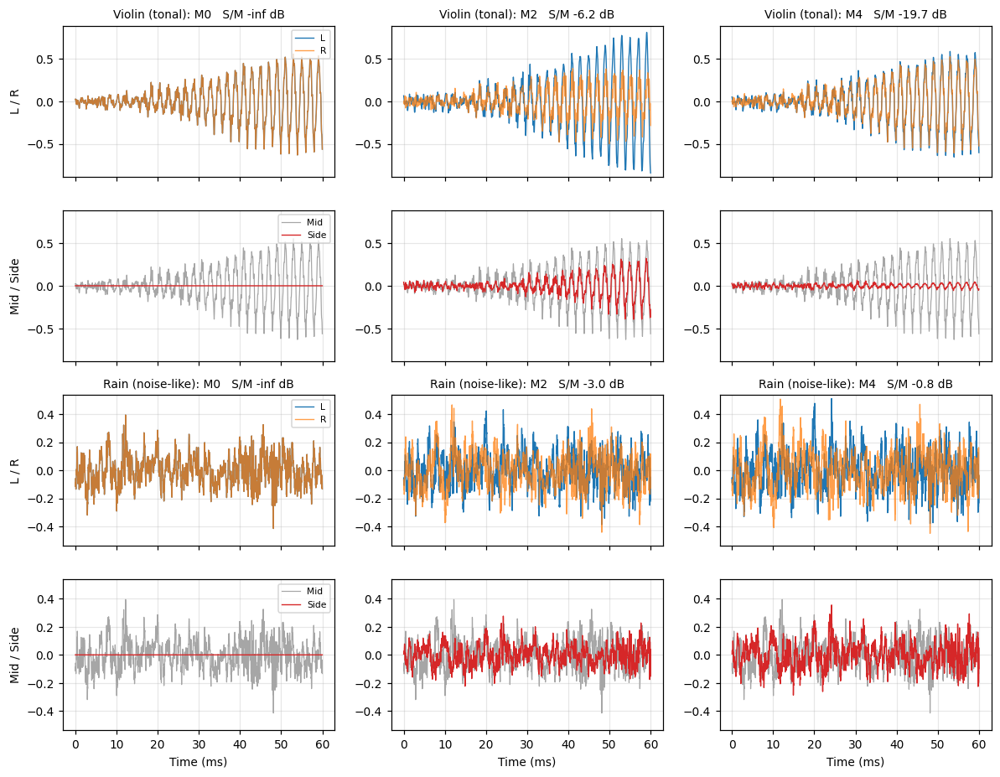

In [16]:
EXAMPLES = {'violin_solo_bach_hahn': 'Violin (tonal)', 'rain_ambience': 'Rain (noise-like)'}
VIEW = {'M0': m0, 'M2': m2, 'M4': lambda y: m4(y)[:2]}
WIN = int(0.06 * FS)
fig, ax = plt.subplots(4, len(VIEW), figsize=(11, 8.5), sharex=True)
for r, (k, name) in enumerate(EXAMPLES.items()):
    y = clips[k]
    t, _, rms = features(y)
    gf = m4(y)[3]
    loud = np.flatnonzero(rms >= np.percentile(rms, 75))
    i = loud[np.argmin(np.abs(gf[loud] - np.median(gf[loud])))]
    sl = slice(int(t[i] * FS) - WIN // 2, int(t[i] * FS) + WIN // 2)
    tt = np.arange(WIN) / FS * 1000
    st = {m: fn(y)[:2] for m, fn in VIEW.items()}
    lim = 1.05 * max((np.abs(np.stack(lr)[:, sl]).max() for lr in st.values()))
    print(f'{name}: {t[i] - 0.03:.2f}-{t[i] + 0.03:.2f} s of the analysed clip, M4 gain {m4(y)[2][sl].mean():.2f}')
    for c, (m, (L, R)) in enumerate(st.items()):
        a, b = (ax[2 * r, c], ax[2 * r + 1, c])
        a.plot(tt, L[sl], lw=0.9, label='L')
        a.plot(tt, R[sl], lw=0.9, alpha=0.75, label='R')
        b.plot(tt, (L[sl] + R[sl]) / 2, c='0.65', lw=0.8, label='Mid')
        b.plot(tt, (L[sl] - R[sl]) / 2, c='C3', lw=0.9, label='Side')
        smr = sm_db(L[sl], R[sl])
        a.set_title(f'{name}: {m}   S/M {smr:.1f} dB' if np.isfinite(smr) else f'{name}: {m}   S/M -inf dB', fontsize=9)
        for z in (a, b):
            z.set_ylim(-lim, lim)
        print(f'   {m}: S/M {smr:6.1f} dB, ICC {icc(L[sl], R[sl]):.3f}')
    ax[2 * r, 0].set_ylabel('L / R')
    ax[2 * r + 1, 0].set_ylabel('Mid / Side')
    ax[2 * r, 0].legend(loc='upper right', fontsize=7)
    ax[2 * r + 1, 0].legend(loc='upper right', fontsize=7)
for a in ax[-1]:
    a.set_xlabel('Time (ms)')
save(fig, 'stereo_waveforms')
